# Projet — Classification d'images de bout en bout

**Cours :** Réseaux de neurones convolutifs (CNN) — 30 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 4 h · **Barème :** 20 points

---

## Objectifs

- Mener un projet complet : données, modèle, entraînement, évaluation.
- Interpréter les résultats (matrice de confusion, rappel par classe, top-k).
- Visualiser les zones de décision par Grad-CAM.
- Rédiger une conclusion critique sur les limites du modèle.

## Travail demandé

1. Mener le projet jusqu'au bout (le notebook doit s'exécuter entièrement).
2. Ajouter au moins **une expérience de régularisation** supplémentaire, mesurée.
3. Rendre le notebook exécuté accompagné d'une conclusion écrite.

## Mode d'emploi

- Exécuter les cellules **dans l'ordre**. L'entraînement tourne sur **CPU** : quelques minutes.
- Les cellules **« À vous »** sont évaluées.
- Toutes les graines sont fixées : deux exécutions donnent le même résultat.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)
device = 'cpu'
print('torch', torch.__version__, '| appareil :', device)

torch 2.15.0+cpu | appareil : cpu


## Projet — Classification d'images réelles de bout en bout

**Jeu de données.** Le projet du cours porte sur **GTSRB** (panneaux routiers, 43 classes,
39 209 images d'entraînement). **GTSRB n'est pas accessible depuis cette machine** (serveur
injoignable) : le projet utilise donc **CIFAR-10**, autre jeu réel de 60 000 images couleur
32×32 en 10 classes. **Le code est identique** : pour passer à GTSRB, il suffit de remplacer
le `DataLoader` (une cellule est prévue pour cela en fin de notebook).

**Contrainte :** machine **CPU**, pas de GPU. Sous-ensemble + peu d'époques.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

moy, ect = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
tf_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(moy, ect)])
tf_test = transforms.Compose([transforms.ToTensor(), transforms.Normalize(moy, ect)])

tr_full = datasets.CIFAR10("../data", train=True, download=True, transform=tf_train)
te_full = datasets.CIFAR10("../data", train=False, download=True, transform=tf_test)
CLASSES = ['avion', 'automobile', 'oiseau', 'chat', 'cerf',
           'chien', 'grenouille', 'cheval', 'bateau', 'camion']
N_TR, N_TE = 8000, 2000
tr = Subset(tr_full, range(N_TR)); te = Subset(te_full, range(N_TE))
train_loader = DataLoader(tr, batch_size=128, shuffle=True)
test_loader = DataLoader(te, batch_size=256)
print(N_TR, "images d'entrainement |", N_TE, "de test |", len(CLASSES), "classes")

  0%|          | 0.00/170M [00:00<?, ?B/s]

  0%|          | 32.8k/170M [00:00<26:01, 109kB/s]

  0%|          | 65.5k/170M [00:00<26:06, 109kB/s]

  0%|          | 98.3k/170M [00:00<26:26, 107kB/s]

  0%|          | 131k/170M [00:01<26:20, 108kB/s] 

  0%|          | 164k/170M [00:01<26:23, 108kB/s]

... (5,186 outputs left out)

100%|█████████▉| 170M/170M [27:02<00:00, 77.1kB/s]

100%|█████████▉| 170M/170M [27:02<00:00, 77.3kB/s]

100%|██████████| 170M/170M [27:02<00:00, 105kB/s] 

8000 images d'entrainement | 2000 de test | 10 classes


C:\Users\HP\AppData\Local\Temp\ipykernel_14276\354079429.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ax.imshow(np.transpose(im, (1, 2, 0)) * np.array(ect) + np.array(moy))
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..1.0000000339984894].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..1.0000000532150268].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.858823568725586].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.8470588460922241].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.870588246011734].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.941176483297348].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.9843137263298034].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..1.0000000339984894].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.9686274481058121].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.9659271205684234e-08..0.976470601940155].


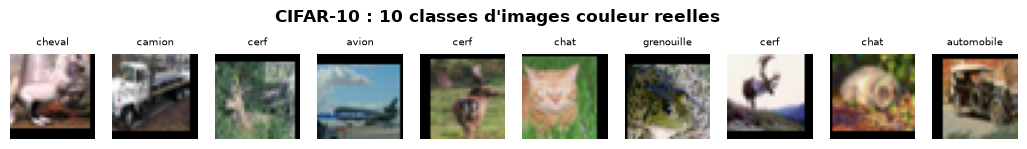

In [3]:
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for ax, im, yy in zip(axes, xb[:10], yb[:10]):
    ax.imshow(np.transpose(im, (1, 2, 0)) * np.array(ect) + np.array(moy))
    ax.set_title(CLASSES[int(yy)], fontsize=7.5); ax.axis("off")
plt.suptitle("CIFAR-10 : 10 classes d'images couleur reelles", fontweight="bold")
plt.show()

In [4]:
class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def bloc(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.Conv2d(cout, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.MaxPool2d(2))
        self.corps = nn.Sequential(bloc(3, 32), bloc(32, 64), bloc(64, 128))
        self.tete = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(128*4*4, 256),
                                  nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.tete(self.corps(x))

modele = CNN().to(device)
print("parametres :", f"{sum(p.numel() for p in modele.parameters()):,}".replace(",", " "))

parametres : 815 018


In [5]:
opt = torch.optim.Adam(modele.parameters(), lr=1.5e-3, weight_decay=5e-4)
EPOQUES = 6
plan = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOQUES)
pf = nn.CrossEntropyLoss()
hist = {"perte": [], "train": [], "test": []}

def evalue(m, loader):
    m.eval(); b = t = 0
    with torch.no_grad():
        for x, y in loader:
            b += (m(x).argmax(1) == y).sum().item(); t += y.size(0)
    return b / t

EPOQUES = 8
for ep in range(EPOQUES):
    modele.train(); acc_p = 0
    for x, y in train_loader:
        opt.zero_grad(); perte = pf(modele(x), y)
        perte.backward(); opt.step(); hist["perte"].append(perte.item())
    plan.step()
    a_tr = evalue(modele, train_loader); a_te = evalue(modele, test_loader)
    hist["train"].append(a_tr); hist["test"].append(a_te)
    print(f"epoque {ep+1}/{EPOQUES}  perte={np.mean(hist['perte'][-94:]):.4f}"
          f"  train={a_tr:.1%}  test={a_te:.1%}")

print("\nexactitude test :", f"{hist['test'][-1]:.2%}")

epoque 1/8  perte=2.0124  train=33.5%  test=32.1%


epoque 2/8  perte=1.7477  train=33.4%  test=35.4%


epoque 3/8  perte=1.5546  train=40.8%  test=45.4%


epoque 4/8  perte=1.4312  train=49.9%  test=46.6%


epoque 5/8  perte=1.3088  train=56.7%  test=54.9%


epoque 6/8  perte=1.2289  train=58.5%  test=57.4%


epoque 7/8  perte=1.1811  train=59.0%  test=58.1%


epoque 8/8  perte=1.1661  train=58.8%  test=58.0%

exactitude test : 58.00%


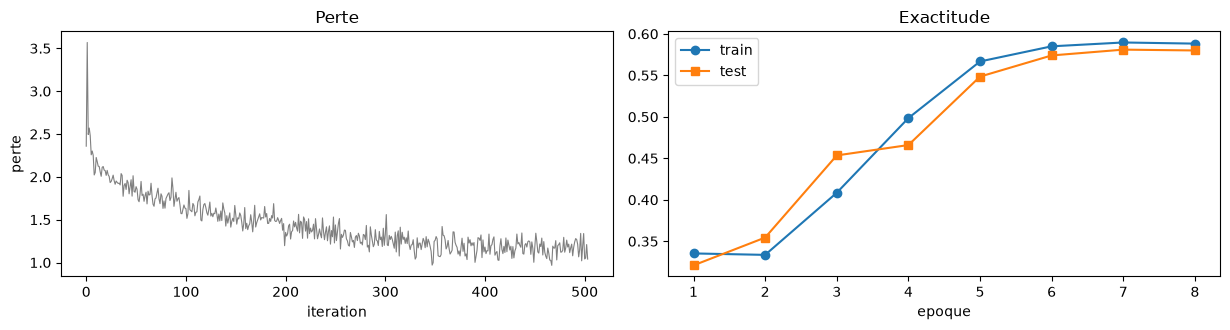

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.4))
axes[0].plot(hist["perte"], lw=.8, color="grey"); axes[0].set_title("Perte")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("perte")
axes[1].plot(range(1, EPOQUES+1), hist["train"], "o-", label="train")
axes[1].plot(range(1, EPOQUES+1), hist["test"], "s-", label="test")
axes[1].set_title("Exactitude"); axes[1].set_xlabel("epoque"); axes[1].legend()
plt.tight_layout(); plt.show()

## Évaluation détaillée

L'exactitude globale ne suffit pas : on regarde classe par classe.

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

modele.eval(); P, Y = [], []
with torch.no_grad():
    for x, y in test_loader:
        P.append(modele(x).argmax(1)); Y.append(y)
P = torch.cat(P).numpy(); Y = torch.cat(Y).numpy()

M = confusion_matrix(Y, P)
print(classification_report(Y, P, target_names=CLASSES, digits=3, zero_division=0))

              precision    recall  f1-score   support

       avion      0.595     0.577     0.585       196
  automobile      0.763     0.717     0.740       198
      oiseau      0.321     0.462     0.379       195
        chat      0.398     0.332     0.362       199
        cerf      0.538     0.283     0.371       198
       chien      0.441     0.530     0.482       185
  grenouille      0.649     0.778     0.707       216
      cheval      0.759     0.622     0.684       193
      bateau      0.644     0.816     0.720       217
      camion      0.812     0.640     0.716       203

    accuracy                          0.580      2000
   macro avg      0.592     0.576     0.574      2000
weighted avg      0.595     0.580     0.578      2000



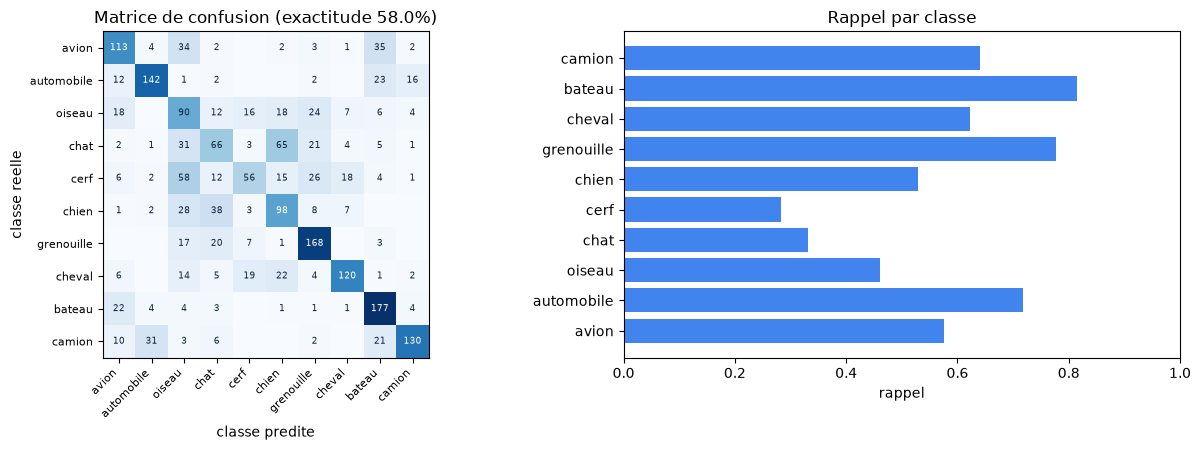

classe la plus difficile : cerf (rappel 28.3%)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(M, cmap="Blues")
axes[0].set_xticks(range(10)); axes[0].set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
axes[0].set_yticks(range(10)); axes[0].set_yticklabels(CLASSES, fontsize=8)
axes[0].set_xlabel("classe predite"); axes[0].set_ylabel("classe reelle")
axes[0].set_title(f"Matrice de confusion (exactitude {M.trace()/M.sum():.1%})")
for i in range(10):
    for j in range(10):
        if M[i, j]:
            axes[0].text(j, i, M[i, j], ha="center", va="center", fontsize=6.2,
                         color="white" if M[i, j] > M.max()*.55 else "#10243E")
axes[0].grid(False)
rappel = M.diagonal() / M.sum(1)
axes[1].barh(CLASSES, rappel, color="#1F6FEB", alpha=.85)
axes[1].set_xlim(0, 1); axes[1].set_xlabel("rappel")
axes[1].set_title("Rappel par classe")
plt.tight_layout(); plt.show()

pire = int(np.argmin(rappel))
print(f"classe la plus difficile : {CLASSES[pire]} (rappel {rappel[pire]:.1%})")

## Top-k et robustesse

Un modèle peut se tromper tout en classant la bonne réponse au second rang. On mesure
aussi sa résistance à une transformation géométrique simple.

In [9]:
corrects = []
with torch.no_grad():
    for x, y in test_loader:
        s = modele(x)
        top5 = s.topk(5, dim=1).indices
        corrects.append((top5 == y[:, None]).any(1))
top5_acc = torch.cat(corrects).float().mean().item()
print(f"top-1 : {hist['test'][-1]:.2%}")
print(f"top-5 : {top5_acc:.2%}")

# robustesse : rotation de 20 degres
tf_rot = transforms.Compose([transforms.RandomRotation((-20, -20)), transforms.ToTensor(),
                             transforms.Normalize(moy, ect)])
te_rot = Subset(datasets.CIFAR10("../data", train=False, download=True, transform=tf_rot), range(N_TE))
print(f"top-1 sous rotation -20 deg : {evalue(modele, DataLoader(te_rot, batch_size=256)):.2%}")

top-1 : 58.00%
top-5 : 96.05%


top-1 sous rotation -20 deg : 42.50%


## Gradient-weighted Class Activation Mapping (Grad-CAM)

Quelles régions de l'image ont pesé dans la décision ? On remonte le gradient de la
classe prédite jusqu'à la dernière carte convolutive.

C:\Users\HP\AppData\Local\Temp\ipykernel_14276\630729553.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  aff = np.transpose(img, (1, 2, 0)) * np.array(ect) + np.array(moy)


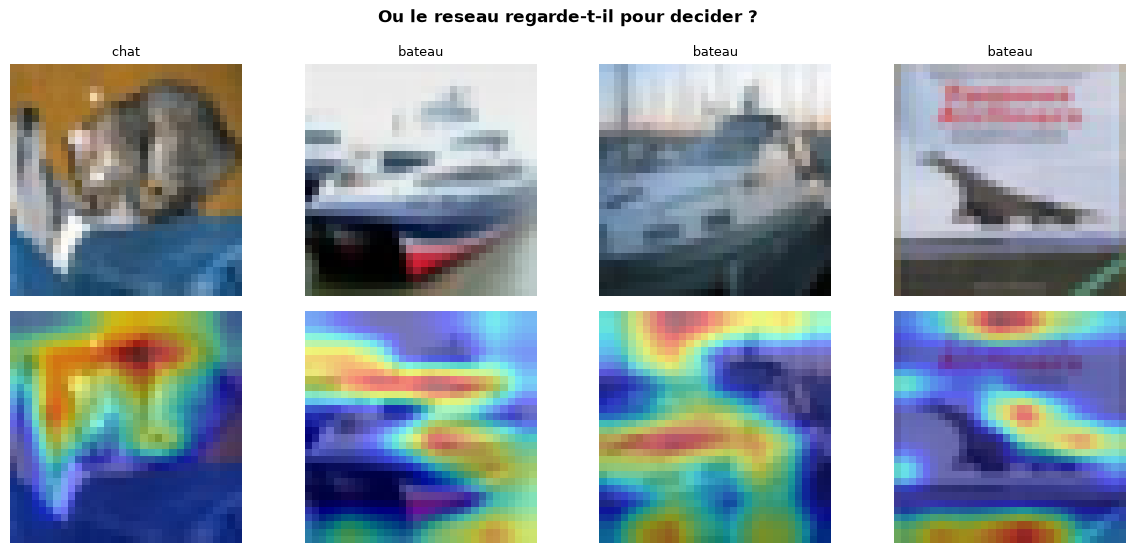

In [10]:
def gradcam(modele, img, classe=None):
    modele.eval()
    x = img.unsqueeze(0).to(device)
    if classe is None:
        with torch.no_grad():
            classe = int(modele(x).argmax(1))
    cartes, grads = [], []
    cible = modele.corps[-1][3]          # derniere couche convolutive du corps
    h = cible.register_forward_hook(lambda m, i, o: cartes.append(o))
    hs = cible.register_full_backward_hook(lambda m, gi, go: grads.append(gi[0]))
    sortie = modele(x)[0, classe]; modele.zero_grad(); sortie.backward()
    h.remove(); hs.remove()
    A, G = cartes[0][0], grads[0][0]
    poids = G.mean(dim=(1, 2))
    cam = torch.relu((poids[:, None, None] * A).sum(0))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().numpy(), classe

xb, yb = next(iter(test_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6))
for j in range(4):
    img = xb[j]
    cam, cl = gradcam(modele, img)
    aff = np.transpose(img, (1, 2, 0)) * np.array(ect) + np.array(moy)
    axes[0, j].imshow(np.clip(aff, 0, 1)); axes[0, j].set_title(CLASSES[cl], fontsize=9)
    axes[1, j].imshow(np.clip(aff, 0, 1))
    axes[1, j].imshow(F.interpolate(torch.tensor(cam)[None, None], size=(32, 32),
                                    mode="bilinear")[0, 0], cmap="jet", alpha=.5)
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_ylabel("image", fontsize=9); axes[1, 0].set_ylabel("Grad-CAM", fontsize=9)
plt.suptitle("Ou le reseau regarde-t-il pour decider ?", fontweight="bold")
plt.tight_layout(); plt.show()

## Passer à GTSRB (panneaux routiers)

Le code du projet est identique : il suffit de changer le jeu de données. Téléchargez
GTSRB manuellement, puis :

```python
# racine contenant les dossiers gtsrb-german-traffic-sign/ ou le .zip officiel
gtsrb_train = datasets.GTSRB(root="../data", split="train",
                             download=False, transform=tf_train)
gtsrb_test  = datasets.GTSRB(root="../data", split="test",
                             download=False, transform=tf_test)
# 43 classes au lieu de 10 ; adaptez n_classes dans CNN()
```

## Grille d'évaluation du projet (20 points)

| Critère | Points |
|---|---|
| Le notebook s'exécute de bout en bout sans erreur | 4 |
| Le modèle atteint une exactitude de test raisonnable. Repère mesuré sur cette
     machine (CPU, 8 000 images, 8 époques) : **58,0 %** — viser davantage avec
     plus d'époques ou de données, et le justifier | 4 |
| La matrice de confusion est commentée (classes confondues, pourquoi) | 4 |
| Une expérience de régularisation est menée **et mesurée** | 4 |
| Le Grad-CAM est interprété (le réseau regarde-t-il au bon endroit ?) | 2 |
| Conclusion : trois limites honnêtes du modèle | 2 |

**Rappel méthodologique :** un chiffre annoncé sans la commande qui l'a produit ne vaut rien.
Toute valeur de votre rapport doit être reproductible.